In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Datheon Internship - Task 1")
print("Libraries imported successfully!")

Datheon Internship - Task 1
Libraries imported successfully!


In [40]:
import pandas as pd

df = pd.read_csv("Dataset/superstore_sales.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [41]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (10800, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  P

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [42]:
# Check missing values
print("Missing Values in Each Column:")
display(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values in Each Column:


Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


Total Missing Values:
15325

Duplicate Records:
504


In [43]:
profile = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

display(profile)

profile.to_csv("Output/data_profile.csv", index=False)

print("Data profile saved successfully!")

,Column Name,Data Type,Missing Values,Unique Values
0,Row ID,str,0,10001
1,Order ID,str,0,5015
2,Order Date,str,806,1236
3,Ship Date,str,806,1334
4,Ship Mode,str,806,4
5,Customer ID,str,806,793
6,Customer Name,str,806,793
7,Segment,str,806,3
8,Country,str,806,1
9,City,str,806,531


Data profile saved successfully!


In [44]:
# Create a copy of the original dataset
df_clean = df.copy()

# Convert Row ID into numeric format
df_clean["Row ID"] = pd.to_numeric(
    df_clean["Row ID"],
    errors="coerce"
)

# Remove invalid rows
df_clean = df_clean.dropna(
    subset=["Row ID"]
).copy()

# Convert Row ID into integer
df_clean["Row ID"] = df_clean["Row ID"].astype(int)

# Check duplicate records
print("Duplicate Records:",
      df_clean.duplicated().sum())

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Display cleaned dataset information
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
display(df_clean.isnull().sum())

Duplicate Records: 0

Original Dataset Shape: (10800, 21)
Cleaned Dataset Shape: (9994, 21)

Missing Values After Cleaning:


Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [45]:
# Convert Order Date
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Convert Ship Date
df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Extract Year
df_clean["Year"] = df_clean["Order Date"].dt.year

# Extract Month
df_clean["Month"] = df_clean["Order Date"].dt.month

# Extract Month Name
df_clean["Month Name"] = df_clean["Order Date"].dt.month_name()

# Extract Year-Month
df_clean["Year-Month"] = (
    df_clean["Order Date"].dt.to_period("M").astype(str)
)

display(df_clean.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017,11,November,2017-11
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017,11,November,2017-11
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017,6,June,2017-06
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016,10,October,2016-10
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016,10,October,2016-10


In [46]:
# Calculate total sales
total_sales = df_clean["Sales"].sum()

# Calculate total profit
total_profit = df_clean["Profit"].sum()

# Calculate total orders
total_orders = df_clean["Order ID"].nunique()

# Calculate total customers
total_customers = df_clean["Customer ID"].nunique()

# Calculate total quantity
total_quantity = df_clean["Quantity"].sum()

# Calculate profit margin
profit_margin = (total_profit / total_sales) * 100

# Display results
print("========== BUSINESS PERFORMANCE ==========")

print("Total Sales:", round(total_sales, 2))

print("Total Profit:", round(total_profit, 2))

print("Total Orders:", total_orders)

print("Total Customers:", total_customers)

print("Total Quantity:", total_quantity)

print("Profit Margin:", round(profit_margin, 2), "%")

========== BUSINESS PERFORMANCE ==========
Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Total Quantity: 37873.0
Profit Margin: 12.47 %


In [47]:
category_analysis = df_clean.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

display(category_analysis)

,Category,Total_Sales,Total_Profit,Total_Quantity
0,Furniture,741999.7953,18451.2728,8028.0
1,Office Supplies,719047.0320,122490.8008,22906.0
2,Technology,836154.0330,145454.9481,6939.0


In [48]:
region_analysis = df_clean.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

display(region_analysis)

,Region,Total_Sales,Total_Profit
0,Central,501239.8908,39706.3625
1,East,678781.2400,91522.7800
2,South,391721.9050,46749.4303
3,West,725457.8245,108418.4489


In [49]:
segment_analysis = df_clean.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

display(segment_analysis)

,Segment,Total_Sales,Total_Profit,Total_Orders
0,Consumer,1.161401e+06,134119.2092,2586
1,Corporate,7.061464e+05,91979.1340,1514
2,Home Office,4.296531e+05,60298.6785,909


In [50]:
import os

os.makedirs("Output", exist_ok=True)

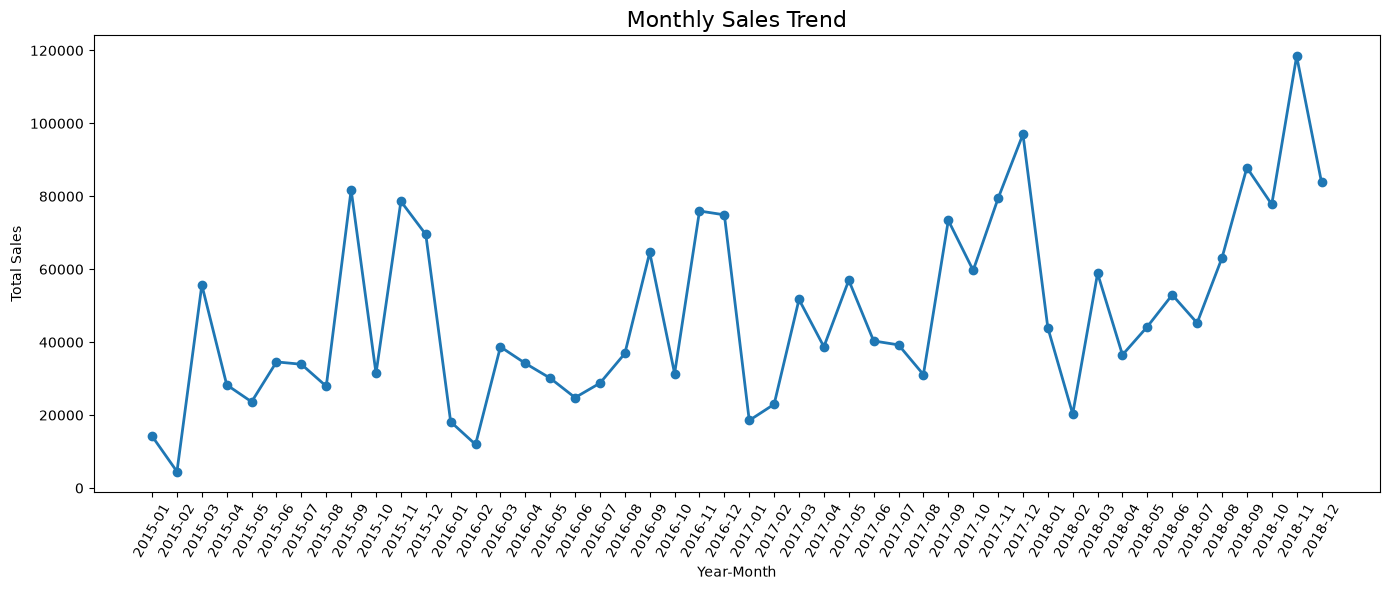

In [51]:
monthly_sales = df_clean.groupby(
    "Year-Month"
)["Sales"].sum().sort_index()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)

plt.tight_layout()
plt.savefig("Output/Monthly_Sales.png", dpi=300)
plt.show()

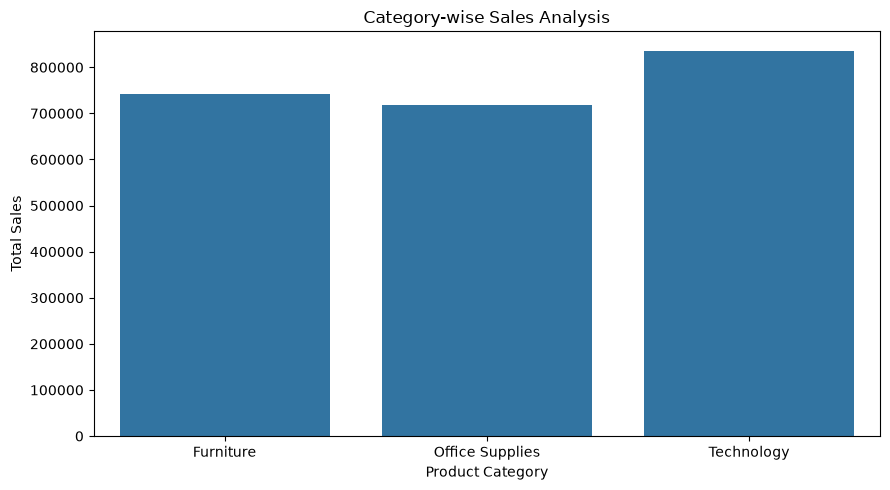

In [52]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales"
)

plt.title("Category-wise Sales Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.savefig("Output/Category_Sales.png", dpi=300)
plt.show()

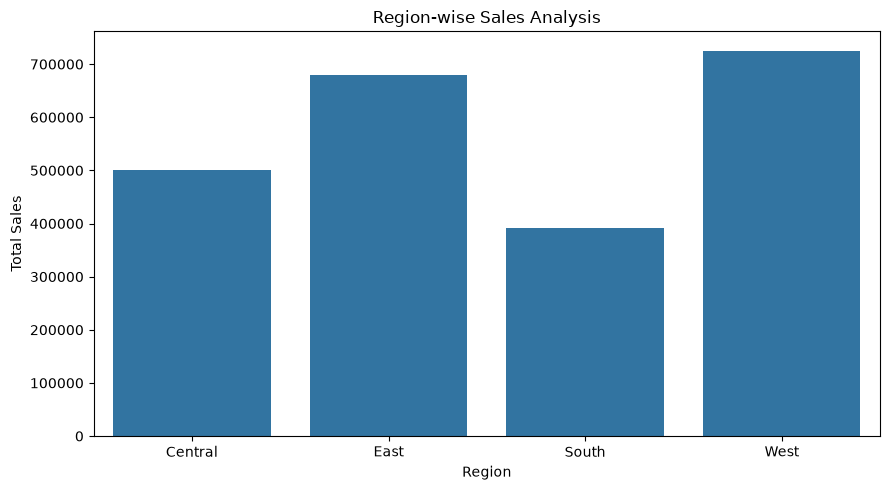

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Sales"
)

plt.title("Region-wise Sales Analysis")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.savefig("Output/Region_Sales.png", dpi=300)
plt.show()

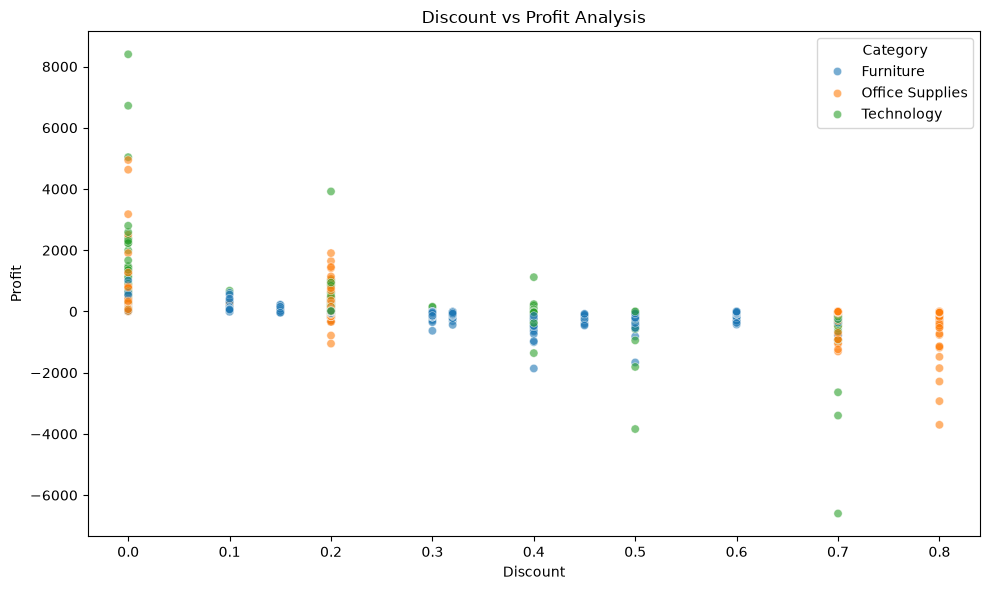

In [54]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.title("Discount vs Profit Analysis")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()
plt.savefig("Output/Discount_Profit.png", dpi=300)
plt.show()

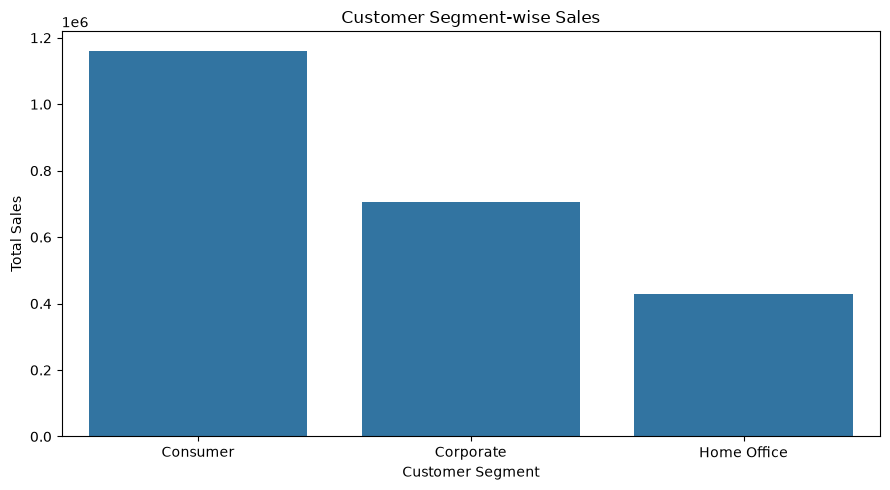

In [55]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Sales"
)

plt.title("Customer Segment-wise Sales")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.savefig("Output/Customer_Segment.png", dpi=300)
plt.show()

## Executive Business Findings

### 1. Category-wise Sales Performance
Technology generates the highest revenue among the three product categories, indicating strong customer demand for technology products.

### 2. Regional Sales Performance
The West region contributes the highest sales compared with the other regions, showing strong regional business performance.

### 3. Customer Segment Analysis
The Consumer segment generates the highest revenue, followed by Corporate and Home Office segments.

### 4. Monthly Sales Seasonality
Monthly sales analysis helps identify seasonal patterns and high-performing months. These insights can support inventory and sales planning.

### 5. Discount Sensitivity Analysis
The correlation between discount and profit is -0.219, indicating a negative relationship. The analysis also shows that several higher discount levels have negative average profits. Therefore, the company should carefully review discount policies to maintain profitability.

### Conclusion
The exploratory data analysis identifies important sales patterns, customer purchasing behavior, regional performance and profitability trends. These insights can help businesses improve sales strategies and make data-driven decisions.

In [56]:
# Calculate correlation
correlation = df_clean["Discount"].corr(
    df_clean["Profit"]
)

print("Discount vs Profit Correlation:",
      round(correlation, 3))

# Analyze average profit by discount
discount_analysis = df_clean.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

display(discount_analysis)

Discount vs Profit Correlation: -0.219


,Discount,Average_Profit,Total_Sales,Total_Orders
0,0.00,66.900292,1.087908e+06,2644
1,0.10,96.055074,5.436935e+04,89
2,0.15,27.288298,2.755852e+04,51
3,0.20,24.702572,7.645944e+05,2407
4,0.30,-45.679636,1.032267e+05,211
5,0.32,-88.560656,1.449346e+04,27
6,0.40,-111.927429,1.164178e+05,185
7,0.45,-226.646464,5.484974e+03,10
8,0.50,-310.703456,5.891854e+04,64
9,0.60,-43.077212,6.644700e+03,127


In [57]:
df_clean.to_csv(
    "Output/cleaned_superstore.csv",
    index=False
)

print("Final cleaned dataset saved!")

Final cleaned dataset saved!
